In [26]:
import matplotlib.pyplot as plt, pandas as pd, numpy as np

In [33]:
df = pd.read_csv('dataset/redmi6.csv', encoding='latin-1')
df.head()

,Review Title,Customer name,Rating,Date,Category,Comments,Useful
0,Another Midrange killer Smartphone by Xiaomi,Rishikumar Thakur,4.0 out of 5 stars,on 1 October 2018,Display,Another Midrange killer Smartphone by Xiaomi\n...,
1,vry small size mobile,Raza ji,3.0 out of 5 stars,on 15 September 2018,Others,All ok but vry small size mobile,7 people found this helpful
2,Full display not working in all application.,Vaibhav Patel,3.0 out of 5 stars,on 18 September 2018,Others,Quite good,7 people found this helpful
3,Value for Money,Amazon Customer,5.0 out of 5 stars,on 28 September 2018,Display,Redmi has always have been the the king of bud...,2 people found this helpful
4,Not worth for the money,Sudhakaran Wadakkancheri,2.0 out of 5 stars,on 18 September 2018,Others,worst product from MI. I am a hardcore fan of ...,6 people found this helpful


In [ ]:
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords", quiet=True)
stop_words = set(stopwords.words("english"))

# Remove rows with missing values
df = df.dropna()

# Convert text to lowercase
df[1] = df[1].astype(str).str.lower()

# Remove punctuation and special characters
df[1] = df[1].str.replace(r"[^\w\s]", "", regex=True)

df[2] = df[2].astype(str).str.extract(r"(\d+\.?\d*)").astype(float)

# Remove stopwords
df[5] = df[5].astype(str).apply(
    lambda x: " ".join(word for word in x.split() if word not in stop_words)
)

df["sentiment"] = df[2].apply(lambda x: 1 if x >= 4 else 0)

In [20]:
df.head()

,0,1,2,3,4,5,6,sentiment
1,Another Midrange killer Smartphone by Xiaomi,rishikumar thakur,4.0,on 1 October 2018,Display,Another Midrange killer Smartphone Xiaomi Majo...,,1
2,vry small size mobile,raza ji,3.0,on 15 September 2018,Others,All ok vry small size mobile,7 people found this helpful,0
3,Full display not working in all application.,vaibhav patel,3.0,on 18 September 2018,Others,Quite good,7 people found this helpful,0
4,Value for Money,amazon customer,5.0,on 28 September 2018,Display,Redmi always king budget segment.And yet anoth...,2 people found this helpful,1
5,Not worth for the money,sudhakaran wadakkancheri,2.0,on 18 September 2018,Others,worst product MI. I hardcore fan MI. But one r...,6 people found this helpful,0


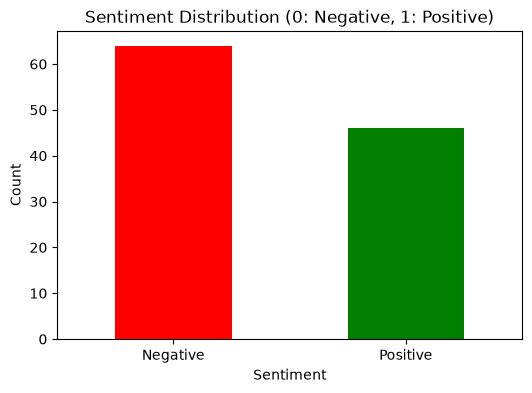

In [27]:
sentiment_counts = df['sentiment'].value_counts()
plt.figure(figsize=(6, 4))
sentiment_counts.plot(kind='bar', color=['red', 'green'])
plt.title('Sentiment Distribution (0: Negative, 1: Positive)')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.xticks(ticks=[0, 1], labels=['Negative', 'Positive'], rotation=0)
plt.show()

In [31]:
df.columns

Index([0, 1, 2, 3, 4, 5, 6, 'sentiment'], dtype='object')